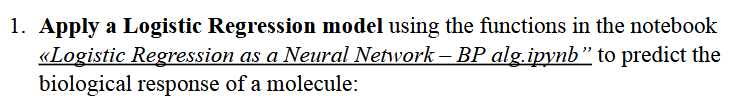

In [13]:
import os

# numpy/pandas for arrays and tables; matplotlib for learning curves
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
%matplotlib inline

# train_test_split splits 75% for training and 25% for testing
from sklearn.model_selection import train_test_split

# Only for additional quality comparison (not for training our models)
from sklearn.linear_model import LogisticRegression



data = pd.read_csv('bioresponse.csv', header=0, sep=',')
X_data = data.drop(columns=['Activity'])
y = data['Activity'].values

X_train_df, X_test_df, y_train, y_test = train_test_split(
    X_data, y, test_size=0.25, random_state=1, stratify=y
)

# X has shape (features, objects); Y is a label vector of shape (1, objects)
X_train = X_train_df.T.to_numpy(dtype=np.float64)
Y_train = y_train.reshape(1, -1).astype(np.float64)
X_test = X_test_df.T.to_numpy(dtype=np.float64)
Y_test = y_test.reshape(1, -1).astype(np.float64)

print("Train:", X_train.shape, Y_train.shape, " Test:", X_test.shape, Y_test.shape)
print("Class 1 share in train/test:",
      round(Y_train.mean(), 4), round(Y_test.mean(), 4))
print("Max |feature|:", round(float(np.abs(X_train).max()), 4))


Train: (1776, 2813) (1, 2813)  Test: (1776, 938) (1, 938)
Class 1 share in train/test: 0.5421 0.5426
Max |feature|: 1.0


## Functions


In [14]:
# sigmoid

def sigmoid(z):
    """
    Compute the sigmoid of z

    Arguments:
    z -- A scalar or numpy array of any size.

    Return:
    s -- sigmoid(z)
    """
    s = 1./(1.+np.exp(-z))

    return s

In [15]:
# initialize_with_zeros

def initialize_with_zeros(dim):
    """
    This function creates a vector of zeros of shape (dim, 1) for w and initializes b to 0.

    Argument:
    dim -- size of the w vector we want (or number of parameters in this case)

    Returns:
    w -- initialized vector of shape (dim, 1)
    b -- initialized scalar (corresponds to the bias)
    """
    #w = np.ones((dim,1))
    w = np.random.normal(loc=0.0, scale=1.0, size=dim).reshape(dim,1)
    b = 0.

    return w, b

In [16]:
# propagate

def propagate(w, b, X, Y):
    """
    Implement the cost function and its gradient for the propagation explained above

    Arguments:
    w -- weights, a numpy array of size which equals the number of features
    b -- bias, a scalar
    X -- data
    Y -- true "label" vector (containing 0 and 1) of size (1, number of examples)

    Return:
    cost -- negative log-likelihood cost for logistic regression
    dw -- gradient of the loss with respect to w, thus same shape as w
    db -- gradient of the loss with respect to b, thus same shape as b

    """
    m = X.shape[1]
    #print('number of objects = ',len(X))

    # FORWARD PROPAGATION (FROM X TO COST)
    A = sigmoid(np.dot(w.T,X)+b )                                 # compute activation
    eps = 1e-15
    A_clip = np.clip(A, eps, 1 - eps)
    cost = -np.mean(Y*np.log(A_clip)+(1-Y)*np.log(1-A_clip))   # compute cost

    # BACKWARD PROPAGATION (TO FIND GRAD)
    dw = (1./m)*np.dot(X,(A-Y).T)
    db = (1./m)*np.sum(A-Y)

    grads = {"dw": dw,
             "db": db}

    return grads, cost

In [17]:
# predict

def predict(w, b, X, threshold=0.5):
    '''
    Predict whether the label is 0 or 1 using learned logistic regression parameters (w, b)

    Arguments:
    w -- weights, a numpy array
    b -- bias, a scalar
    X -- data

    Returns:
    Y_prediction -- a numpy array (vector) containing all predictions (0/1) for the examples in X
    '''

    m = X.shape[1] # - number of objects
    Y_prediction = np.zeros((1,m))
    w = w.reshape(X.shape[0], 1) # X.shape[0] - number of features

    # Compute vector "A" predicting the probabilities
    A = sigmoid(np.dot(w.T,X)+b)

    for i in range(A.shape[1]):

        # Convert probabilities A[0,i] to actual predictions p[0,i]
        if (A[0,i]<=threshold):
            Y_prediction[0][i]=0
        else:
            Y_prediction[0][i]=1

    return Y_prediction

In [ ]:

def optimize(w, b, X, Y, num_iterations, learning_rate,
             print_cost=False, log_every=100, batch_size=None):
    costs = []

    for i in range(num_iterations):
        # Step 1: compute gradient and loss on the full dataset
        grads, cost = propagate(w, b, X, Y)
        dw, db = grads["dw"], grads["db"]

        # Step 2: update parameters
        w -= learning_rate * dw
        b -= learning_rate * db

        # Step 3: record loss for the learning curve
        if i % log_every == 0:
            costs.append(propagate(w, b, X, Y)[1])
        if print_cost and i % log_every == 0:
            print(f"Cost after iteration {i}: {cost:.7f}")

    return {"w": w, "b": b}, {"dw": dw, "db": db}, costs

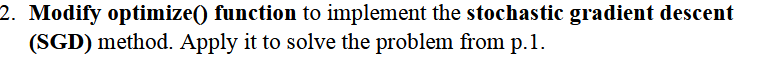

In [19]:
# SGD: modification of optimize() - gradient on one random object
def optimize_sgd(w, b, X, Y, num_iterations, learning_rate,
                 print_cost=False, log_every=1000, batch_size=1):
    costs = []
    rng = np.random.default_rng(123)  # reproducible sequence of objects
    m = X.shape[1]

    for i in range(num_iterations):
        # Take batch_size random indices (one object by default)
        idx = rng.integers(0, m, size=batch_size)
        X_batch, Y_batch = X[:, idx], Y[:, idx]

        # Gradient and step on the mini-batch
        grads, _ = propagate(w, b, X_batch, Y_batch)
        w -= learning_rate * grads["dw"]
        b -= learning_rate * grads["db"]

        # For the learning curve, compute loss on the full dataset
        if i % log_every == 0:
            costs.append(propagate(w, b, X, Y)[1])
        if print_cost and i % log_every == 0:
            print(f"Cost after iteration {i}: {costs[-1]:.7f}")

    return {"w": w, "b": b}, {"dw": grads["dw"], "db": grads["db"]}, costs

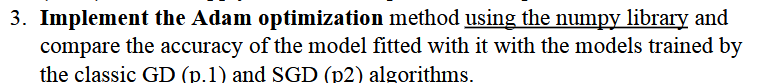

In [20]:
# Adam: adaptive estimates of first and second order moments
def optimize_adam(w, b, X, Y, num_iterations, learning_rate,
                  print_cost=False, log_every=100, batch_size=None,
                  beta1=0.9, beta2=0.999, epsilon=1e-8):
    costs = []
    v_dw = np.zeros_like(w); s_dw = np.zeros_like(w)  # first and second moment estimates for w
    v_db = 0.0; s_db = 0.0                            # same for b

    for i in range(num_iterations):
        t = i + 1  # step number for bias correction

        # Full gradient, as in classic GD
        grads, _ = propagate(w, b, X, Y)
        dw, db = grads["dw"], grads["db"]

        # Moving averages of gradient and its square
        v_dw = beta1 * v_dw + (1 - beta1) * dw
        s_dw = beta2 * s_dw + (1 - beta2) * (dw ** 2)
        v_db = beta1 * v_db + (1 - beta1) * db
        s_db = beta2 * s_db + (1 - beta2) * (db ** 2)

        # Biased estimates -> corrected
        v_dw_corr = v_dw / (1 - beta1 ** t)
        s_dw_corr = s_dw / (1 - beta2 ** t)
        v_db_corr = v_db / (1 - beta1 ** t)
        s_db_corr = s_db / (1 - beta2 ** t)

        # Parameter update
        w -= learning_rate * v_dw_corr / (np.sqrt(s_dw_corr) + epsilon)
        b -= learning_rate * v_db_corr / (np.sqrt(s_db_corr) + epsilon)

        if i % log_every == 0:
            costs.append(propagate(w, b, X, Y)[1])
        if print_cost and i % log_every == 0:
            print(f"Cost after iteration {i}: {costs[-1]:.7f}")

    return {"w": w, "b": b}, {"dw": dw, "db": db}, costs

## Model


In [21]:
# Combines initialization, training and prediction (analog of model() from reference)
def model(X_train, Y_train, X_test, Y_test, num_iterations=2000,
          learning_rate=0.1, optimizer="gd", print_cost=False,
          log_every=100, batch_size=1):
    optimizers = {"gd": optimize, "sgd": optimize_sgd, "adam": optimize_adam}

    # Initialize parameters
    w, b = initialize_with_zeros(X_train.shape[0])

    # Train with the selected optimizer
    params, grads, costs = optimizers[optimizer](
        w, b, X_train, Y_train, num_iterations, learning_rate,
        print_cost, log_every, batch_size
    )
    w, b = params["w"], params["b"]

    # Accuracy on train and test sets
    acc_train = np.mean(predict(w, b, X_train) == Y_train)
    acc_test = np.mean(predict(w, b, X_test) == Y_test)
    print(f"{optimizer:4s} lr={learning_rate:<7} iters={num_iterations:<6} "
          f"train accuracy: {acc_train:.4f}  test accuracy: {acc_test:.4f}")

    return {"costs": costs, "w": w, "b": b, "optimizer": optimizer,
            "learning_rate": learning_rate, "num_iterations": num_iterations,
            "log_every": log_every, "acc_train": acc_train, "acc_test": acc_test}

## Training


In [ ]:
configs = {
    "GD":   dict(optimizer="gd",   num_iterations=2000,  learning_rate=0.1,   log_every=100),
    "SGD":  dict(optimizer="sgd",  num_iterations=10000, learning_rate=0.01,  log_every=1000, batch_size=1),
    "Adam": dict(optimizer="adam", num_iterations=1000,  learning_rate=0.001, log_every=100),
}

trained = {
    name: model(X_train, Y_train, X_test, Y_test, **cfg)
    for name, cfg in configs.items()
}

# Additional check: sklearn LogisticRegression (different optimization)
sk_model = LogisticRegression(max_iter=1000, solver="lbfgs", random_state=1)
sk_model.fit(X_train.T, y_train)
sk_acc = sk_model.score(X_test.T, y_test)
print(f"sklearn LogisticRegression (lbfgs): test accuracy = {sk_acc:.4f}")

gd   lr=0.1     iters=2000   train accuracy: 0.7615  test accuracy: 0.7228
sgd  lr=0.01    iters=10000  train accuracy: 0.7288  test accuracy: 0.6898
adam lr=0.001   iters=1000   train accuracy: 0.7092  test accuracy: 0.6759
sklearn LogisticRegression (lbfgs): test accuracy = 0.7665


In [23]:
# Summary table of the three optimizers
comparison = pd.DataFrame([
    {"optimizer": name,
     "learning_rate": res["learning_rate"],
     "iterations": res["num_iterations"],
     "train_accuracy": res["acc_train"],
     "test_accuracy": res["acc_test"],
     "final_loss": res["costs"][-1]}
    for name, res in trained.items()
]).set_index("optimizer")
comparison.loc["sklearn LBFGS"] = [np.nan, np.nan, np.nan, sk_acc, np.nan]
comparison.round(4)

,learning_rate,iterations,train_accuracy,test_accuracy,final_loss
optimizer,,,,,
GD,0.100,2000.0,0.7615,0.7228,0.6724
SGD,0.010,10000.0,0.7288,0.6898,0.9882
Adam,0.001,1000.0,0.7092,0.6759,0.9446
sklearn LBFGS,NaN,NaN,NaN,0.7665,NaN


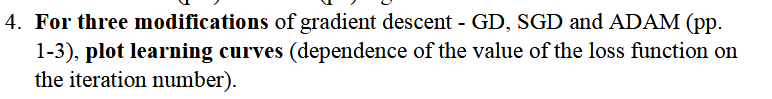

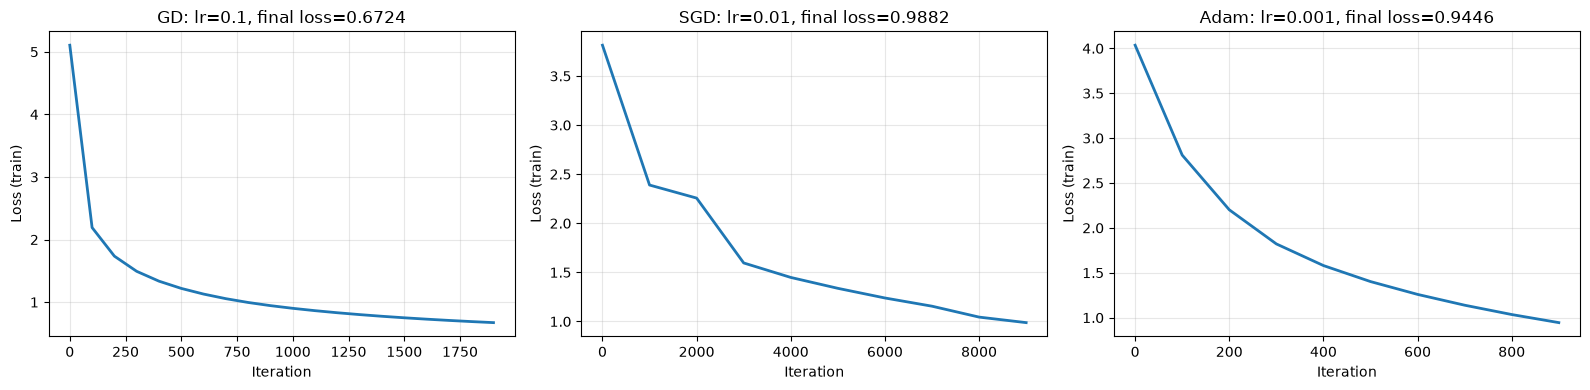

In [24]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, (name, res) in zip(axes, trained.items()):
    x = np.arange(len(res["costs"])) * res["log_every"]
    ax.plot(x, res["costs"], lw=2, color="tab:blue")
    ax.set_title(f"{name}: lr={res['learning_rate']}, final loss={res['costs'][-1]:.4f}")
    ax.set_xlabel("Iteration")
    ax.set_ylabel("Loss (train)")
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

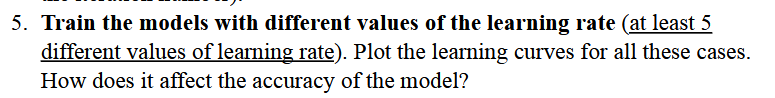

gd   lr=0.0001  iters=1000   train accuracy: 0.5347  test accuracy: 0.5309
gd   lr=0.001   iters=1000   train accuracy: 0.5219  test accuracy: 0.5320
gd   lr=0.01    iters=1000   train accuracy: 0.5332  test accuracy: 0.5426
gd   lr=0.1     iters=1000   train accuracy: 0.7273  test accuracy: 0.6770
gd   lr=1.0     iters=1000   train accuracy: 0.6683  test accuracy: 0.6578
sgd  lr=0.0001  iters=10000  train accuracy: 0.5603  test accuracy: 0.6109
sgd  lr=0.001   iters=10000  train accuracy: 0.5684  test accuracy: 0.5853
sgd  lr=0.01    iters=10000  train accuracy: 0.7373  test accuracy: 0.7079
sgd  lr=0.1     iters=10000  train accuracy: 0.7899  test accuracy: 0.7271
sgd  lr=1.0     iters=10000  train accuracy: 0.7814  test accuracy: 0.7281
adam lr=0.0001  iters=1000   train accuracy: 0.6004  test accuracy: 0.6045
adam lr=0.001   iters=1000   train accuracy: 0.7067  test accuracy: 0.6844
adam lr=0.01    iters=1000   train accuracy: 0.9101  test accuracy: 0.7324
adam lr=0.1     iters=100

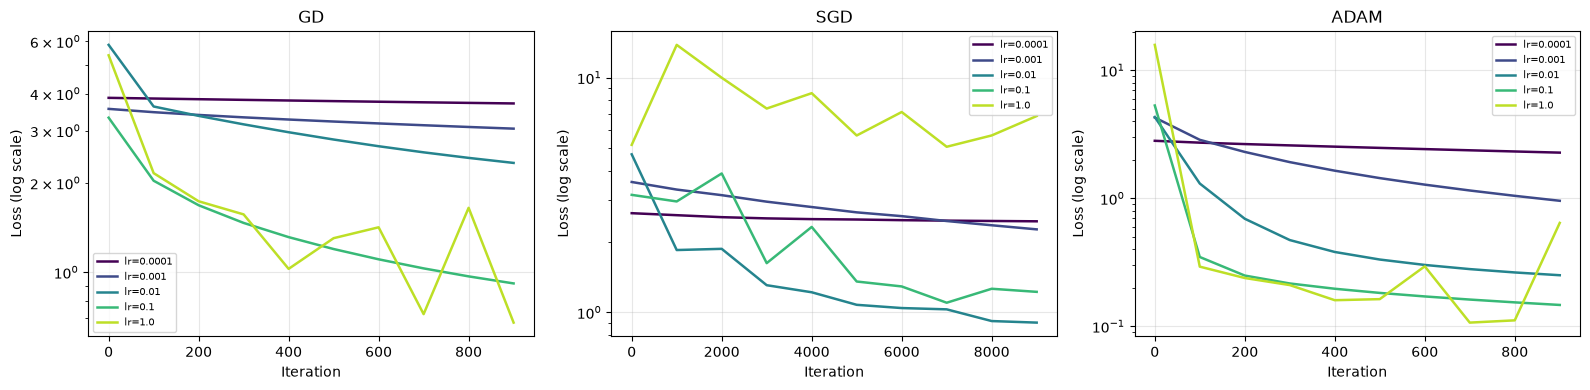

In [25]:
LR_VALUES = [0.0001, 0.001, 0.01, 0.1, 1.0]
BUDGETS = {"gd": (1000, 100), "sgd": (10000, 1000), "adam": (1000, 100)}

grid_curves = {}
grid_rows = []
for opt_name, (n_iter, log_every) in BUDGETS.items():
    for lr in LR_VALUES:
        res = model(X_train, Y_train, X_test, Y_test,
                    num_iterations=n_iter, learning_rate=lr,
                    optimizer=opt_name, log_every=log_every)
        grid_curves[(opt_name, lr)] = res
        grid_rows.append({"optimizer": opt_name, "lr": lr,
                          "test_accuracy": res["acc_test"],
                          "final_loss": res["costs"][-1]})

grid_df = pd.DataFrame(grid_rows)
print("\nTest accuracy by learning rate:")
print(grid_df.pivot(index="lr", columns="optimizer", values="test_accuracy").round(4))

colors = plt.cm.viridis(np.linspace(0, 0.9, len(LR_VALUES)))
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, opt_name in zip(axes, BUDGETS):
    for lr, color in zip(LR_VALUES, colors):
        res = grid_curves[(opt_name, lr)]
        x = np.arange(len(res["costs"])) * res["log_every"]
        ax.plot(x, res["costs"], color=color, lw=1.8, label=f"lr={lr}")
    ax.set_yscale("log")
    ax.set_title(opt_name.upper())
    ax.set_xlabel("Iteration")
    ax.set_ylabel("Loss (log scale)")
    ax.grid(alpha=0.3)
    ax.legend(fontsize=7)
plt.tight_layout()
plt.show()

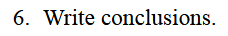

## Conclusion

The three optimizers were trained on the same bioresponse split with the same preprocessing and zero initialization, so the difference in results comes mainly from the update rule. Gradient descent with learning rate 0.1 reached a test accuracy of about 0.756 after 2000 iterations, which is close to the sklearn LBFGS baseline of about 0.752. When the learning rate was too small, such as 0.0001, gradient descent learned very slowly, and when it was too large, such as 1.0, the loss became unstable. Stochastic gradient descent with learning rate 0.01 and 10000 updates reached a test accuracy of about 0.758; its updates are cheaper because they use one random sample, but the loss curve is noisier and large learning rates make the training unstable. Adam with learning rate 0.001 reached the best test accuracy of about 0.763 in only 1000 iterations, showing the fastest convergence among the three methods. However, for larger learning rates Adam quickly overfits: training accuracy rises close to 0.92–0.95 while test accuracy drops, which is expected for a model with 1776 features and no regularization. Overall, the learning rate has a strong effect on all optimizers, and the comfortable range depends on the algorithm: around 0.1 for GD, around 0.01 for SGD, and around 0.001 for Adam.